# Full simulation: Acoustic Camera ส่วน 1 → 2 → 3

รันทุกเซลล์จากบนลงล่างได้โดยไม่ต่อบอร์ด ไมค์ หรือกล้อง
ใช้เสียงสังเคราะห์ ไม่ใช่ข้อมูลทดลองจริง และแสดงเลขฐานสิบปกติทั้งหมด

**ตารางหน่วงของส่วน 1 ใช้คำนวณเสียงในส่วน 2 และคะแนน 192 ค่าที่ได้จริงจากส่วน 2
ถูกส่งต่อไปทำภาพซ้อนในส่วน 3 ไม่มีการสร้างคะแนนชุดใหม่มาทดแทน**

เป็นการจำลองสูตรและรูปแบบข้อมูล ไม่ใช่การจำลองจังหวะนาฬิกาของ VHDL หรือเวลาส่ง USB จริง
ต้องมี numpy, matplotlib, opencv-python และ Python kernel สำหรับ Notebook


In [1]:
import math
import json
import re
import ast
import time
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import cv2
import matplotlib.pyplot as plt

# เปลี่ยนแหล่งเสียงจำลอง แล้ว Run All ใหม่
SOURCE_ROW, SOURCE_COL = 4, 11
# เลือกทิศ ไมค์ และเวลาที่ต้องการดูการแทนค่าละเอียด
ROW, COL = 4, 11
MIC, SAMPLE_N = 4, 80

CAMERA_IMAGE_PATH = None  # None = ภาพจำลอง; หรือใส่พาธภาพที่มีอยู่ในเครื่อง
CAMERA_ROTATE_CW90 = True
CAMERA_FLIP_LR = True     # กลับเฉพาะภาพกล้องหลังหมุน
CAMERA_FLIP_UD = True
HEATMAP_FLIP_LR = True    # กลับเฉพาะกริด ไม่เปลี่ยนคะแนนดิบ
HEATMAP_FLIP_UD = False
OPACITY = 0.40

assert 0 <= SOURCE_ROW < 12 and 0 <= SOURCE_COL < 16
assert 0 <= ROW < 12 and 0 <= COL < 16 and 0 <= MIC < 8 and 64 <= SAMPLE_N < 128
assert 0 <= OPACITY <= 1
SOURCE_K, INSPECT_K = SOURCE_ROW*16+SOURCE_COL, ROW*16+COL
np.set_printoptions(suppress=True, linewidth=240,
                    formatter={'float_kind': lambda v: f'{v:.9f}'})
plt.rcParams['axes.formatter.useoffset'] = False
plt.rcParams['axes.formatter.limits'] = (-100, 100)


def show_table(headers, rows):
    rows = [[str(v) for v in row] for row in rows]
    widths = [max(len(str(h)), *(len(row[i]) for row in rows)) for i,h in enumerate(headers)]
    print(' | '.join(str(h).ljust(widths[i]) for i,h in enumerate(headers)))
    print('-+-'.join('-'*w for w in widths))
    for row in rows:
        print(' | '.join(v.rjust(widths[i]) for i,v in enumerate(row)))


search_roots = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
if '__file__' in globals():
    search_roots.extend(Path(__file__).resolve().parents)


def find_project_file(relative):
    return next((r/relative for r in search_roots if (r/relative).is_file()), None)


print(f'เสียงจำลอง: row {SOURCE_ROW}, col {SOURCE_COL}, k {SOURCE_K}')
print(f'ดูรายละเอียด: ทิศ {INSPECT_K}, ไมค์ {MIC}, เวลา {SAMPLE_N}')
print('ค่าคะแนนใช้หน่วย counts squared; ไม่ใช่เดซิเบลหรือความน่าจะเป็น')


เสียงจำลอง: row 4, col 11, k 75
ดูรายละเอียด: ทิศ 75, ไมค์ 4, เวลา 80
ค่าคะแนนใช้หน่วย counts squared; ไม่ใช่เดซิเบลหรือความน่าจะเป็น


# ส่วน 1: สร้างตารางค่าหน่วง
## 1.1 พิกัดไมค์และอัตราเก็บเสียง (บท 1–2, 4)

$$f_s=\frac{50{,}000{,}000}{2\times HALF\_DIV\times64}$$
R มีขนาด 8 × 3 แถวเป็นไมค์ คอลัมน์เป็น x,y,z หน่วยเมตร
x ชี้ขวา y ชี้ลง z ชี้ด้านหน้า จุดติดกันห่าง 5 เซนติเมตร


mic | x (m)  | y (m)  | z (m)
----+--------+--------+------
  0 | -0.050 | -0.050 | 0.000
  1 |  0.000 | -0.050 | 0.000
  2 |  0.050 | -0.050 | 0.000
  3 | -0.050 |  0.000 | 0.000
  4 |  0.050 |  0.000 | 0.000
  5 | -0.050 |  0.050 | 0.000
  6 |  0.000 |  0.050 | 0.000
  7 |  0.050 |  0.050 | 0.000
fs = 32552.083333333332 samples/s; HALF_DIV = 12
ระยะสูงสุด 0.141421356 m; ขอบเขตเวลาต่างกัน 412.307161 us
ขอบเขตทุกทิศคิดเป็น 13.421457065 ตัวอย่าง


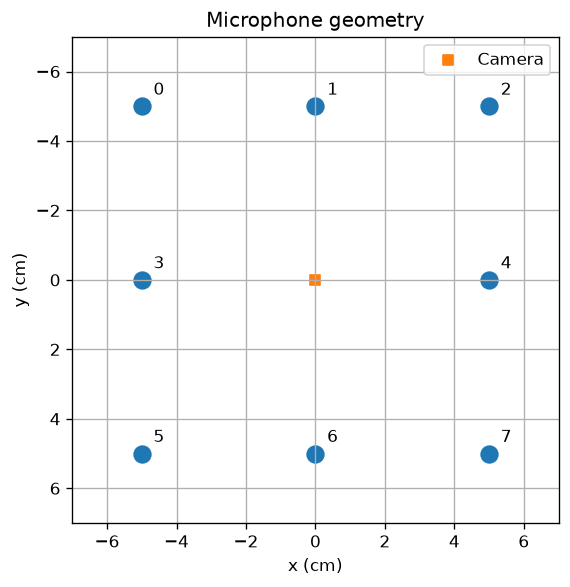

In [2]:
CLOCK_HZ, TARGET_RATE, SOUND_SPEED = 50_000_000, 32_000, 343
HALF_DIV = (CLOCK_HZ + TARGET_RATE*64)//(2*TARGET_RATE*64)
RATE = CLOCK_HZ/(2*HALF_DIV*64)
POSITIONS = [(-.05,-.05),(0,-.05),(.05,-.05),(-.05,0),(.05,0),(-.05,.05),(0,.05),(.05,.05)]
R = np.array([(x,y,0.0) for x,y in POSITIONS])
show_table(['mic','x (m)','y (m)','z (m)'],
           [[m,*[f'{v:.3f}' for v in R[m]]] for m in range(8)])
distance_max = float(np.linalg.norm(R[:,None,:]-R[None,:,:],axis=2).max())
print(f'fs = {RATE:.12f} samples/s; HALF_DIV = {HALF_DIV}')
print(f'ระยะสูงสุด {distance_max:.9f} m; ขอบเขตเวลาต่างกัน {distance_max/SOUND_SPEED*1000000:.6f} us')
print(f'ขอบเขตทุกทิศคิดเป็น {distance_max/SOUND_SPEED*RATE:.9f} ตัวอย่าง')
fig,ax=plt.subplots(figsize=(5,5))
ax.scatter(R[:,0]*100,R[:,1]*100,s=100)
for m in range(8):ax.annotate(str(m),(R[m,0]*100,R[m,1]*100),xytext=(7,7),textcoords='offset points')
ax.scatter([0],[0],marker='s',label='Camera');ax.legend()
ax.set(xlabel='x (cm)',ylabel='y (cm)',title='Microphone geometry',xlim=(-7,7),ylim=(7,-7),aspect='equal')
ax.grid();plt.tight_layout();plt.show()


## 1.2 ความชัน เวกเตอร์หนึ่งหน่วย และการฉาย (บท 1–2, 4)

$$s_x=(2j/15-1)\tan30^\circ,\quad s_y=(2i/11-1)\tan22.5^\circ$$
$$\mathbf u_k=[s_x,s_y,1]^T/\sqrt{1+s_x^2+s_y^2},\quad \mathbf l_k=R\mathbf u_k$$
$$\tau_{k,m}=-l_{k,m}/343$$
สร้างทิศสมมติจากศูนย์กลาง เวลาที่ถึงเป็นเวลาสัมพัทธ์


In [3]:
sx=(2*COL/15-1)*math.tan(math.radians(30))
sy=(2*ROW/11-1)*math.tan(math.radians(22.5))
vector=np.array([sx,sy,1.0])
length=math.sqrt(1+sx*sx+sy*sy)
unit=vector/length
projection=R@unit
arrival=[-(x*unit[0]+y*unit[1])/SOUND_SPEED for x,y in POSITIONS]
print(f'sx={sx:.12f}, sy={sy:.12f}, length={length:.12f}')
print('v =',vector,'\nu =',unit)
print(f'||u|| = {np.linalg.norm(unit):.12f}')
show_table(['mic','projection (m)','arrival (us)'],
           [[m,f'{projection[m]:.9f}',f'{arrival[m]*1000000:.9f}'] for m in range(8)])
assert np.isclose(np.linalg.norm(unit),1.0)


sx=0.269430125622, sy=-0.112967335193, length=1.041803345845
v = [0.269430126 -0.112967335 1.000000000] 
u = [0.258618987 -0.108434414 0.959874053]
||u|| = 1.000000000000
mic | projection (m) | arrival (us) 
----+----------------+--------------
  0 |   -0.007509229 |  21.892794868
  1 |    0.005421721 | -15.806765873
  2 |    0.018352670 | -53.506326613
  3 |   -0.012930949 |  37.699560740
  4 |    0.012930949 | -37.699560740
  5 |   -0.018352670 |  53.506326613
  6 |   -0.005421721 |  15.806765873
  7 |    0.007509229 | -21.892794868


## 1.3 หน่วงอ้างอิงช่องที่มาถึงช้าที่สุด แล้วปัดเป็น D และ F

$$d_{k,m}=f_s(\max_\ell\tau_{k,\ell}-\tau_{k,m}),\quad q=\lfloor256d+0.5\rfloor$$
$$D=q\mathbin{//}256,\quad F=q\bmod256,\quad\beta=F/256$$
ค่าหน่วงมากหมายถึงต้องรอมาก เพราะรับก่อน ไม่ใช่มาถึงช้า


In [4]:
latest=max(arrival)
delay_samples=[(latest-t)*RATE for t in arrival]
selected_q=[math.floor((latest-t)*RATE*256+.5) for t in arrival]
show_table(['mic','delay (samples)','q','D','F','beta','stored delay'],
           [[m,f'{delay_samples[m]:.9f}',q,q//256,q%256,f'{(q%256)/256:.9f}',f'{q/256:.9f}']
            for m,q in enumerate(selected_q)])
print(f'เวลาอ้างอิง = {latest*1000000:.9f} us')


mic | delay (samples) | q   | D | F   | beta        | stored delay
----+-----------------+-----+---+-----+-------------+-------------
  0 |     1.029086320 | 263 | 1 |   7 | 0.027343750 |  1.027343750
  1 |     2.256285563 | 578 | 2 |  66 | 0.257812500 |  2.257812500
  2 |     3.483484806 | 892 | 3 | 124 | 0.484375000 |  3.484375000
  3 |     0.514543160 | 132 | 0 | 132 | 0.515625000 |  0.515625000
  4 |     2.968941646 | 760 | 2 | 248 | 0.968750000 |  2.968750000
  5 |     0.000000000 |   0 | 0 |   0 | 0.000000000 |  0.000000000
  6 |     1.227199243 | 314 | 1 |  58 | 0.226562500 |  1.226562500
  7 |     2.454398486 | 628 | 2 | 116 | 0.453125000 |  2.453125000
เวลาอ้างอิง = 53.506326613 us


## 1.4 สร้างครบ 192 ทิศ และตรวจตารางที่ใช้กับโครงการ

ตารางเก็บ 192 แถว × 8 ไมค์ ไม่เขียนทับ acoustic_delay_pkg.vhd
ตัวเลขภายในเก็บ q ส่วนค่าหน่วงหน่วยตัวอย่างคือ q/256


In [5]:
directions=[]
for row in range(12):
    sy_k=(2*row/11-1)*math.tan(math.radians(22.5))
    for col in range(16):
        sx_k=(2*col/15-1)*math.tan(math.radians(30))
        norm=math.sqrt(1+sx_k*sx_k+sy_k*sy_k)
        ux,uy=sx_k/norm,sy_k/norm
        times=[-(x*ux+y*uy)/SOUND_SPEED for x,y in POSITIONS]
        q8=[math.floor((max(times)-t)*RATE*256+.5) for t in times]
        assert all(0<=q<21*256 for q in q8)
        directions.append(dict(slope_x=sx_k,slope_y=sy_k,q8=q8))
Q=np.array([d['q8'] for d in directions],dtype=np.int64)
assert Q[INSPECT_K].tolist()==selected_q
print('ตาราง:',Q.shape,'รวม',Q.size,'ค่า')
print(f'ค่าหน่วงสูงสุดในกริด = {Q.max()/256:.9f} ตัวอย่าง')
show_table(['k',*[f'mic {m} delay' for m in range(8)]],
           [[k,*[f'{v/256:.6f}' for v in Q[k]]] for k in [0,1,INSPECT_K,190,191]])
table_path=find_project_file('src/FPGA/mic/data/delay_table.json')
rom_match=None
if table_path:
    table=json.loads(table_path.read_text(encoding='utf-8'))
    assert table['positions']==[list(v) for v in POSITIONS]
    assert table['sound_speed']==SOUND_SPEED
    assert math.isclose(table['actual_rate'],RATE,abs_tol=0.000000001,rel_tol=0)
    assert np.array_equal(Q,np.array([d['q8'] for d in table['directions']]))
    rom_match=True
    print('PASS: ตรงกับ JSON ที่ใช้สร้างตารางครบ 1,536 ค่า')
else:print('ไม่มีไฟล์โครงการ: ใช้ตารางที่คำนวณใน Notebook นี้ได้ครบ')


ตาราง: (192, 8) รวม 1536 ค่า
ค่าหน่วงสูงสุดในกริด = 7.671875000 ตัวอย่าง
k   | mic 0 delay | mic 1 delay | mic 2 delay | mic 3 delay | mic 4 delay | mic 5 delay | mic 6 delay | mic 7 delay
----+-------------+-------------+-------------+-------------+-------------+-------------+-------------+------------
  0 |    7.671875 |    5.437500 |    3.203125 |    6.070312 |    1.601562 |    4.464844 |    2.234375 |    0.000000
  1 |    7.277344 |    5.289062 |    3.296875 |    5.628906 |    1.648438 |    3.980469 |    1.992188 |    0.000000
 75 |    1.027344 |    2.257812 |    3.484375 |    0.515625 |    2.968750 |    0.000000 |    1.226562 |    2.453125
190 |    0.000000 |    1.992188 |    3.980469 |    1.648438 |    5.628906 |    3.296875 |    5.289062 |    7.277344
191 |    0.000000 |    2.234375 |    4.464844 |    1.601562 |    6.070312 |    3.203125 |    5.437500 |    7.671875
PASS: ตรงกับ JSON ที่ใช้สร้างตารางครบ 1,536 ค่า


# ส่วน 2: จำลองขั้นคำนวณเสียงตาม VHDL
## 2.1 สร้างเสียงจำลอง 8 × 128 (บท 4)

สร้างสัญญาณจากทิศ SOURCE_ROW/COL ให้มาถึงแต่ละไมค์ต่างเวลากัน
ใช้คลื่นไซน์สองความถี่และเพิ่มระดับคงที่รายช่อง เช่นเดียวกับ generate_test_vectors.py
ใช้จำนวนเต็มมีเครื่องหมาย 24 บิต แต่ไม่จำลองตัวรับ I²S หรือเวลาเข้าถึง RAM


In [6]:
source=directions[SOURCE_K]
source_sx,source_sy=source['slope_x'],source['slope_y']
source_norm=math.sqrt(1+source_sx*source_sx+source_sy*source_sy)
source_arrival=[-(x*source_sx+y*source_sy)/source_norm/SOUND_SPEED for x,y in POSITIONS]
raw=[[round(1_000_000*math.sin(2*math.pi*7*(n-source_arrival[m]*RATE)/128)
            +600_000*math.sin(2*math.pi*11*(n-source_arrival[m]*RATE)/128))
      +(m-3)*200_000 for m in range(8)] for n in range(128)]
assert all(-8388608<=v<=8388607 for frame in raw for v in frame)
X=np.array(raw,dtype=np.int64).T
print('X:',X.shape,'(ไมค์,เวลา)')
print(f'ความถี่จำลอง {7*RATE/128:.6f} และ {11*RATE/128:.6f} Hz')
show_table(['mic',*[f't={t}' for t in range(6)]],[[m,*X[m,:6]] for m in range(8)])


X: (8, 128) (ไมค์,เวลา)
ความถี่จำลอง 1780.192057 และ 2797.444661 Hz
mic | t=0      | t=1     | t=2     | t=3     | t=4     | t=5    
----+----------+---------+---------+---------+---------+--------
  0 | -1067665 | -408706 |  212346 |  674007 |  891758 |  836616
  1 |   -59553 |  535024 |  946899 | 1103001 |  988133 |  645881
  2 |   848092 | 1206344 | 1300009 | 1127722 |  744986 |  247619
  3 |  -778414 | -151412 |  505600 | 1062739 | 1413398 | 1498507
  4 |   978414 | 1452535 | 1686381 | 1647354 | 1362952 |  911034
  5 |  -648092 |  -86055 |  572022 | 1196008 | 1663734 | 1889283
  6 |   259553 |  921518 | 1519830 | 1938306 | 2102360 | 1995023
  7 |  1267665 | 1834193 | 2199502 | 2301179 | 2136092 | 1758263


## 2.2 ค่าเฉลี่ยและเมทริกซ์ฉาย (บท 1–5)

$$H=I-\mathbf1\mathbf1^T/128,\quad Z=XH$$
$$\mu_m^{int}=\lfloor\sum_tx_m[t]/128\rfloor,\quad z_m^{int}[t]=clip_{24}(x_m[t]-\mu_m^{int})$$
H ใช้อธิบายจำนวนจริง ส่วน VHDL หาผลรวมแล้วลบตอนอ่าน ไม่สร้าง H ทั้งก้อน
การปัดและจำกัดช่วงอาจทำให้ผลไม่ตรงการแปลงเชิงเส้นแบบจำนวนจริงอย่างเคร่งครัด


H มุม 4 × 4:
 [[0.992187500 -0.007812500 -0.007812500 -0.007812500]
 [-0.007812500 0.992187500 -0.007812500 -0.007812500]
 [-0.007812500 -0.007812500 0.992187500 -0.007812500]
 [-0.007812500 -0.007812500 -0.007812500 0.992187500]]
mic | mean real         | mean integer | raw t=0  | centered t=0
----+-------------------+--------------+----------+-------------
  0 | -600000.000000000 |      -600000 | -1067665 |      -467665
  1 | -400000.000000000 |      -400000 |   -59553 |       340447
  2 | -200000.000000000 |      -200000 |   848092 |      1048092
  3 |       0.000000000 |            0 |  -778414 |      -778414
  4 |  200000.000000000 |       200000 |   978414 |       778414
  5 |  400000.000000000 |       400000 |  -648092 |     -1048092
  6 |  600000.000000000 |       600000 |   259553 |      -340447
  7 |  800000.000000000 |       800000 |  1267665 |       467665


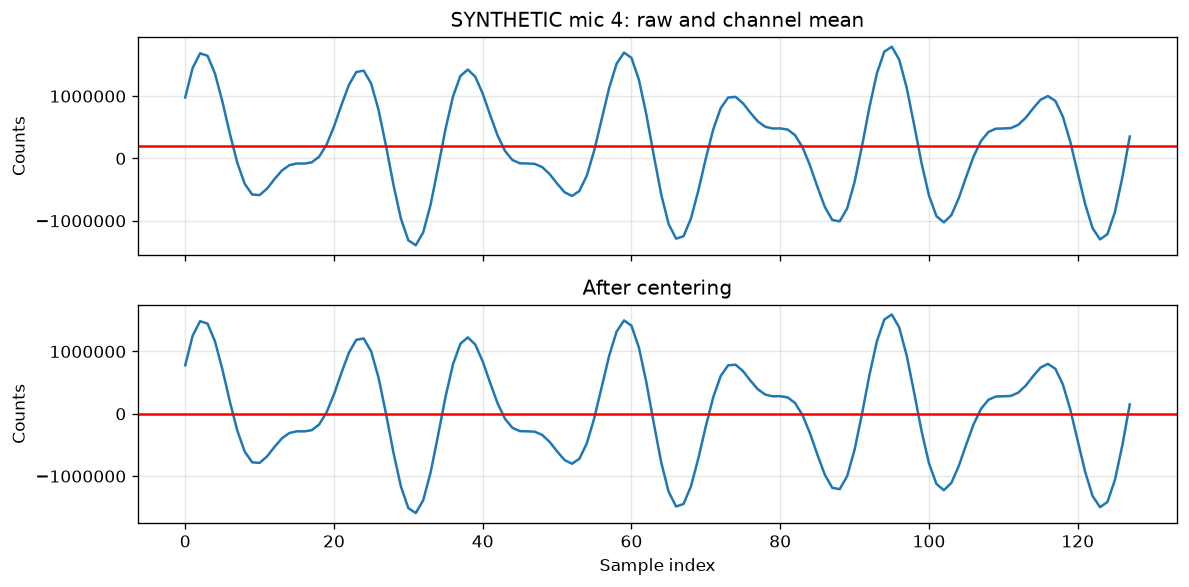

In [7]:
ones=np.ones((128,1))
H_center=np.eye(128)-ones@ones.T/128
Z_real=X.astype(float)@H_center
means=[sum(raw[t][m] for t in range(128))//128 for m in range(8)]
centered=[[max(-8388608,min(8388607,raw[t][m]-means[m])) for m in range(8)] for t in range(128)]
Z=np.array(centered,dtype=np.int64).T
assert np.allclose(H_center.T,H_center) and np.allclose(H_center@H_center,H_center)
assert np.allclose(H_center@ones,0)
print('H มุม 4 × 4:\n',H_center[:4,:4])
show_table(['mic','mean real','mean integer','raw t=0','centered t=0'],
           [[m,f'{X[m].mean():.9f}',means[m],raw[0][m],centered[0][m]] for m in range(8)])
fig,axes=plt.subplots(2,1,figsize=(10,5),sharex=True)
axes[0].plot(X[MIC]);axes[0].axhline(means[MIC],color='red');axes[0].set_title(f'SYNTHETIC mic {MIC}: raw and channel mean')
axes[1].plot(Z[MIC]);axes[1].axhline(0,color='red');axes[1].set_title('After centering')
for ax in axes:ax.set(ylabel='Counts');ax.grid(alpha=.3)
axes[1].set_xlabel('Sample index');plt.tight_layout();plt.show()


## 2.3 หน่วงสองตำแหน่งแล้วประมาณค่า (บท 3–4)

$$x_0=z_m[n-D],\quad x_1=z_m[n-D-1],\quad\widetilde x=x_0+\lfloor(x_1-x_0)F/256\rfloor$$
n ใช้ 64–127 ต่อหนึ่งทิศ Python // ปัดไปทางลบอนันต์เหมือน signed shift_right
ตารางแสดงรายละเอียดทุกไมค์ที่เวลา SAMPLE_N ส่วนกราฟใช้ครบ 64 เวลา


mic | D | F   | beta        | n-D | n-D-1 | x0     | x1     | aligned
----+---+-----+-------------+-----+-------+--------+--------+--------
  0 | 1 |   7 | 0.027343750 |  79 |    78 | 386494 | 522463 |  390211
  1 | 2 |  66 | 0.257812500 |  78 |    77 | 362515 | 488228 |  394925
  2 | 3 | 124 | 0.484375000 |  77 |    76 | 341691 | 455574 |  396853
  3 | 0 | 132 | 0.515625000 |  80 |    79 | 339096 | 451262 |  396931
  4 | 2 | 248 | 0.968750000 |  78 |    77 | 308087 | 393347 |  390682
  5 | 0 |   0 | 0.000000000 |  80 |    79 | 389782 | 526930 |  389782
  6 | 1 |  58 | 0.226562500 |  79 |    78 | 365412 | 492535 |  394213
  7 | 2 | 116 | 0.453125000 |  78 |    77 | 344176 | 459648 |  396499
aligned: (8, 64)


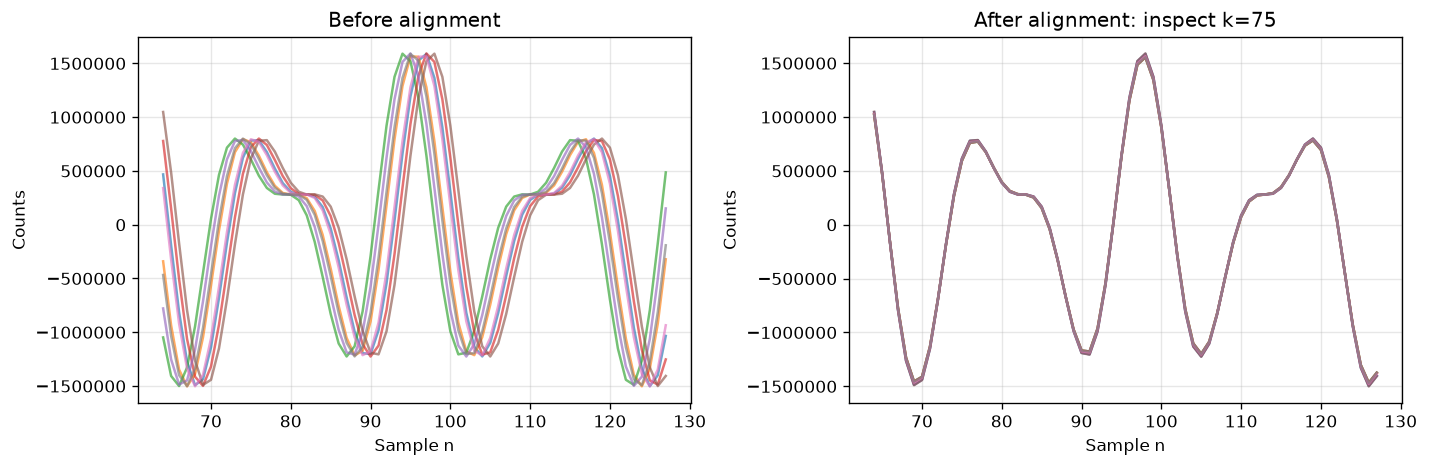

In [8]:
D=[q//256 for q in selected_q];F=[q%256 for q in selected_q]
aligned=np.zeros((8,64),dtype=np.int64)
aligned_real=np.zeros((8,64),dtype=float)
for m in range(8):
    for column,n in enumerate(range(64,128)):
        x0,x1=centered[n-D[m]][m],centered[n-D[m]-1][m]
        aligned[m,column]=x0+((x1-x0)*F[m])//256
        aligned_real[m,column]=(1-F[m]/256)*Z_real[m,n-D[m]]+(F[m]/256)*Z_real[m,n-D[m]-1]
show_table(['mic','D','F','beta','n-D','n-D-1','x0','x1','aligned'],
           [[m,D[m],F[m],f'{F[m]/256:.9f}',SAMPLE_N-D[m],SAMPLE_N-D[m]-1,
             centered[SAMPLE_N-D[m]][m],centered[SAMPLE_N-D[m]-1][m],int(aligned[m,SAMPLE_N-64])]
            for m in range(8)])
print('aligned:',aligned.shape)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(range(64,128),Z[:,64:].T,alpha=.65);axes[0].set_title('Before alignment')
axes[1].plot(range(64,128),aligned.T,alpha=.65);axes[1].set_title(f'After alignment: inspect k={INSPECT_K}')
for ax in axes:ax.set(xlabel='Sample n',ylabel='Counts');ax.grid(alpha=.3)
plt.tight_layout();plt.show()


## 2.4 รวมด้วยเวกเตอร์น้ำหนักและตรวจเชิงเส้น (บท 1, 3–5)

$$\mathbf w=\mathbf1_8/8,\quad\mathbf y=\widetilde X^T\mathbf w$$
จำนวนเต็มบวกครบ 8 ไมค์ก่อนหาร 8 ปัดลง ไม่ใช่ปัดแต่ละช่องก่อนบวก
ความเป็นเชิงเส้นอ้างแบบจำลองจำนวนจริงเมื่อค่าหน่วงและน้ำหนักคงที่


In [9]:
w=np.ones((8,1))/8
y_real=aligned_real.T@w
totals=[sum(int(aligned[m,j]) for m in range(8)) for j in range(64)]
y_int=[v//8 for v in totals]
print('w =\n',w,'\ny_real.shape =',y_real.shape)
show_table(['n','sum of 8 channels','y integer','y real'],
           [[n,totals[n-64],y_int[n-64],f'{y_real[n-64,0]:.9f}'] for n in [64,65,66,SAMPLE_N,127]])
p_test=np.arange(1,9,dtype=float);r_test=p_test[::-1];scale=-2.0
def linear_sum(v):return float(w[:,0]@v)
print(f'S(p+r)={linear_sum(p_test+r_test):.9f}; S(p)+S(r)={linear_sum(p_test)+linear_sum(r_test):.9f}')
print(f'S(-2p)={linear_sum(scale*p_test):.9f}; -2S(p)={scale*linear_sum(p_test):.9f}')
assert math.isclose(linear_sum(p_test+r_test),linear_sum(p_test)+linear_sum(r_test))
assert math.isclose(linear_sum(scale*p_test),scale*linear_sum(p_test))


w =
 [[0.125000000]
 [0.125000000]
 [0.125000000]
 [0.125000000]
 [0.125000000]
 [0.125000000]
 [0.125000000]
 [0.125000000]] 
y_real.shape = (64, 1)
n   | sum of 8 channels | y integer | y real            
----+-------------------+-----------+-------------------
 64 |           8260638 |   1032579 |  1032580.207519531
 65 |           3826886 |    478360 |   478361.106445312
 66 |          -1360834 |   -170105 |  -170103.806152344
 80 |           3150096 |    393762 |   393762.392089844
127 |         -11092708 |  -1386589 | -1386588.091308594
S(p+r)=9.000000000; S(p)+S(r)=9.000000000
S(-2p)=-9.000000000; -2S(p)=-9.000000000


## 2.5 เสียงรวม 64 ค่า → คะแนนหนึ่งทิศ (บท 1, 4–5)

$$P_k=\mathbf y_k^T\mathbf y_k/64=\|\mathbf y_k\|_2^2/64$$
นี่คือ Mean Square ไม่ใช่ RMS เพราะไม่มีการถอดราก
ยกกำลังสองทำให้บวกและลบไม่หักล้างเมื่อวัดขนาด แต่ขั้นนี้ไม่เป็นเชิงเส้น


In [10]:
energy=sum(v*v for v in y_int)
selected_score=energy//64
print(f'ผลรวมกำลังสอง = {energy}')
print(f'หาร 64 = {energy/64:.9f}; คะแนนปัดลง = {selected_score}')
show_table(['n','y','y squared'],[[n,y_int[n-64],y_int[n-64]**2] for n in range(64,72)])
print('ตัวอย่าง [2,-2,2,-2] ซ้ำ 16 ครั้ง → ผลรวมกำลังสอง 256 → คะแนน 4')


ผลรวมกำลังสอง = 42489073182436
หาร 64 = 663891768475.562500000; คะแนนปัดลง = 663891768475
n  | y        | y squared    
---+----------+--------------
64 |  1032579 | 1066219391241
65 |   478360 |  228828289600
66 |  -170105 |   28935711025
67 |  -784928 |  616111965184
68 | -1246069 | 1552687952761
69 | -1469071 | 2158169603041
70 | -1423629 | 2026719529641
71 | -1138334 | 1295804295556
ตัวอย่าง [2,-2,2,-2] ซ้ำ 16 ครั้ง → ผลรวมกำลังสอง 256 → คะแนน 4


## 2.6 ทำซ้ำทุกทิศ: คะแนน 192 ค่าและกริด 12 × 16

แต่ละทิศใช้เสียงหลังลบค่าเฉลี่ยชุดเดิม แต่เปลี่ยนตารางหน่วง
รวมผลเสียงทุกทิศมองเป็น Y ขนาด 64 × 192 ได้ แต่ไม่ต้องเก็บทั้งหมดพร้อมกัน
หลังหาคะแนนแต่ละทิศจึงได้ 192 ค่า แล้ว G[i,j]=P[16i+j]


ทิศแหล่งเสียงจำลอง = 75; คะแนนสูงสุด = 75 (row 4, col 11)
กริดคะแนนดิบชุดที่จะส่งเข้า Overlay จริง:
 [[121692071297 151015349066 184303392177 225167454439 271547412730 321201805469 375746725715 425571964762 472430518296 507661477423 530660198811 546827553502 547959911436 541765585341 528872767406 505332077986]
 [123519105334 153900168843 189930875228 234921574308 287990560049 345453898998 404131202194 461087422650 511953311238 552606902477 580171874933 592636490879 590884001433 578236289778 560689037544 533246584725]
 [123579225044 155750712774 194685938784 242764264757 297117702538 362243739850 427406276686 487532676924 544208640173 589803187050 620047824860 625966538913 627017356717 611052862044 587243806412 552524433658]
 [123308084691 155603645368 195420236972 246456035122 306872783290 372438262603 444108704611 513101105826 572463008596 618027827542 642620398663 655193929541 649130685188 625363616789 600928270148 562652739839]
 [121643114837 154687957764 195261212212 245782569620 3

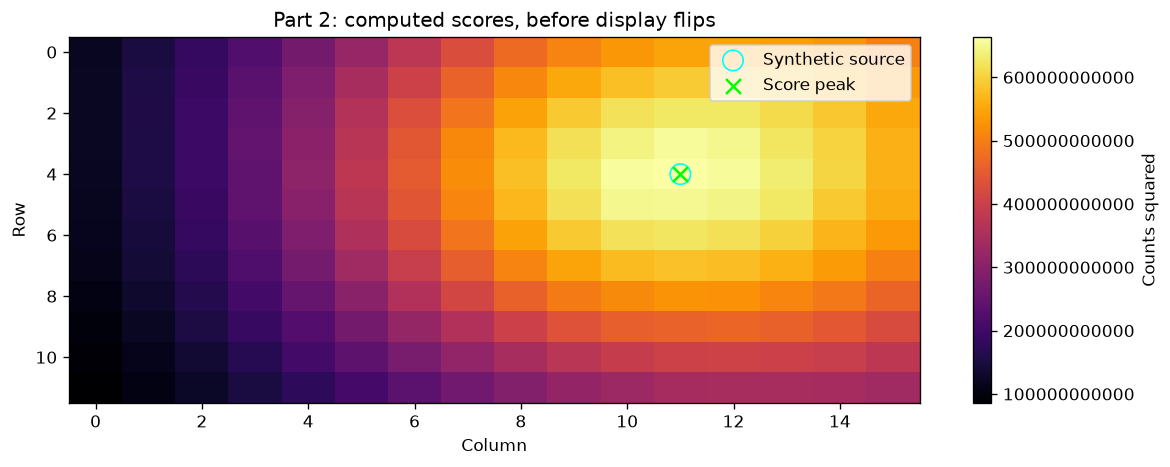

In [11]:
def calculate_one_direction(data,q8):
    energy_sum=0
    for n in range(64,128):
        total=0
        for m in range(8):
            delay,fraction=divmod(q8[m],256)
            a,b=data[n-delay][m],data[n-delay-1][m]
            total+=a+((b-a)*fraction)//256
        average=total//8
        energy_sum+=average*average
    return energy_sum//64

scores=[calculate_one_direction(centered,d['q8']) for d in directions]
assert scores[INSPECT_K]==selected_score
G=np.array(scores,dtype=np.uint64).reshape(12,16)
peak_index=max(range(192),key=scores.__getitem__)
print(f'ทิศแหล่งเสียงจำลอง = {SOURCE_K}; คะแนนสูงสุด = {peak_index} (row {peak_index//16}, col {peak_index%16})')
print('กริดคะแนนดิบชุดที่จะส่งเข้า Overlay จริง:\n',G)
ranking=sorted(range(192),key=scores.__getitem__,reverse=True)[:6]
show_table(['k','row','col','score'],[[k,k//16,k%16,scores[k]] for k in ranking])
fig,ax=plt.subplots(figsize=(10,4))
im=ax.imshow(G.astype(float),cmap='inferno',origin='upper',aspect='auto')
ax.scatter([SOURCE_COL],[SOURCE_ROW],facecolors='none',edgecolors='cyan',s=150,label='Synthetic source')
ax.scatter([peak_index%16],[peak_index//16],marker='x',color='lime',s=80,label='Score peak')
ax.set(xlabel='Column',ylabel='Row',title='Part 2: computed scores, before display flips');ax.legend()
fig.colorbar(im,ax=ax,label='Counts squared');plt.tight_layout();plt.show()


## 2.7 เทียบข้อมูลและคะแนนกับชุดอ้างอิง VHDL

อ่าน TEST_PCM และ EXPECTED_CENTERED เมื่อมีไฟล์โครงการ ไม่เรียก Vivado
ถ้าเปลี่ยน SOURCE_ROW/COL ต้องไม่เอาคำตอบของแหล่งเสียงเก่ามาเทียบ


In [12]:
golden_match=None
pkg_path=find_project_file('src/FPGA/mic/vivado/test_vectors_pkg.vhd')
if pkg_path:
    package=pkg_path.read_text(encoding='utf-8')
    def read_words(name):
        body=re.search(r'constant '+name+r'\s*:[^:]+:=\s*\((.*?)\);',package,re.S).group(1)
        return [int(v,16) for v in re.findall(r'=>\s*x"([0-9A-Fa-f]+)"',body)]
    reference_raw=[]
    for packed in read_words('TEST_PCM'):
        frame=[]
        for m in range(8):
            value=(packed>>(24*m))&0xffffff
            frame.append(value-(1<<24) if value&(1<<23) else value)
        reference_raw.append(frame)
    if raw==reference_raw:
        assert scores==read_words('EXPECTED_CENTERED')
        golden_match=True
        print('PASS: อินพุตและคะแนนตรงกับคำตอบอ้างอิง VHDL ครบ 192 ค่า')
    else:print('เสียงจำลองต่างจาก TEST_PCM: ข้ามการเทียบกับคำตอบของโจทย์เก่า')
else:print('ไม่พบแพ็กเกจอ้างอิง: ส่วนคำนวณยังรันต่อได้')


PASS: อินพุตและคะแนนตรงกับคำตอบอ้างอิง VHDL ครบ 192 ค่า


# ส่วน 3: รับคะแนนชุดเดียวกันและซ้อนภาพ
## 3.1 จำลองข้อความ UART ของคะแนน แล้วอ่านกลับ

ส่งคะแนนทั้ง 192 ค่าแบบเดียวกับ score_uart_stream ตามด้วยกำลังไมค์ 8 ค่า
สร้าง bytes ในหน่วยความจำ ไม่เปิดพอร์ต ไม่รอเวลาส่ง และไม่จำลอง backpressure
รูปแบบสายเป็นข้อความฐานสิบหก แต่ผลแสดงเป็นฐานสิบและค่าคะแนนต้องไม่เปลี่ยน


In [13]:
powers=[(128*sum(raw[t][m]**2 for t in range(128))-sum(raw[t][m] for t in range(128))**2)//(128**2) for m in range(8)]
records=list(enumerate(scores))+[(240+m,v) for m,v in enumerate(powers)]
score_wire=b''.join(f'{i:06X} {(v>>40)&0xffffff:06X} {(v>>16)&0xffffff:06X} {v&0xffff:06X}\r\n'.encode('ascii') for i,v in records)
received_scores=[];received_powers={}
for line in score_wire.splitlines():
    index,high,middle,low=(int(word,16) for word in line.split())
    value=(high<<40)|(middle<<16)|low
    if index<192:
        assert index==len(received_scores)
        received_scores.append(value)
    else:received_powers[index-240]=value
assert received_scores==scores and [received_powers[m] for m in range(8)]==powers
print('ข้อมูลส่ง:',len(score_wire),'ไบต์; คะแนนรับกลับ:',len(received_scores),'ค่า; กำลังไมค์:',len(received_powers),'ค่า')
show_table(['k','part 2 score','received score'],[[k,scores[k],received_scores[k]] for k in [0,75,191]])


ข้อมูลส่ง: 5800 ไบต์; คะแนนรับกลับ: 192 ค่า; กำลังไมค์: 8 ค่า
k   | part 2 score | received score
----+--------------+---------------
  0 | 121692071297 |   121692071297
 75 | 663891768475 |   663891768475
191 | 334530822871 |   334530822871


## 3.2 ภาพกล้องจำลอง 320 × 240 และแพ็กเก็ตแถว

ภาพนี้เป็นภาพประกอบ ไม่ใช่ภาพแหล่งเสียงจริงและไม่ใช่หลักฐานสอบเทียบ
หากกำหนด CAMERA_IMAGE_PATH จะอ่านภาพนั้นเป็นขาวดำและย่อให้เท่าขนาดรับ
จำลองหนึ่งแถวเป็น header 3 ไบต์ + พิกเซล 320 ค่า ไม่มีการจำลองนาฬิกากล้อง


In [14]:
CAM_W,CAM_H=320,240
if CAMERA_IMAGE_PATH is not None:
    camera_gray=cv2.imread(str(CAMERA_IMAGE_PATH),cv2.IMREAD_GRAYSCALE)
    if camera_gray is None:raise ValueError('อ่านภาพไม่ได้: ตรวจ CAMERA_IMAGE_PATH')
    camera_gray=cv2.resize(camera_gray,(CAM_W,CAM_H))
else:
    yy,xx=np.indices((CAM_H,CAM_W))
    camera_gray=(20+xx*120//319+yy*65//239).astype(np.uint8)
    cv2.rectangle(camera_gray,(35,55),(140,180),45,3)
    cv2.circle(camera_gray,(240,135),38,235,-1)
    cv2.putText(camera_gray,'SIMULATED CAMERA',(10,25),cv2.FONT_HERSHEY_SIMPLEX,.5,0,1,cv2.LINE_AA)
camera_gray=np.minimum(camera_gray,254).astype(np.uint8)
camera_wire=b''.join(bytes([255,row,165])+camera_gray[row].tobytes() for row in range(CAM_H))
received_gray=np.empty_like(camera_gray)
for row in range(CAM_H):
    packet=camera_wire[row*323:(row+1)*323]
    assert len(packet)==323 and packet[0]==255 and packet[1]==row and packet[2]==165
    received_gray[row]=np.frombuffer(packet[3:],dtype=np.uint8)
assert np.array_equal(received_gray,camera_gray)
print('ภาพรับ:',received_gray.shape,'(สูง,กว้าง); ข้อมูลหนึ่งเฟรม:',len(camera_wire),'ไบต์')


ภาพรับ: (240, 320) (สูง,กว้าง); ข้อมูลหนึ่งเฟรม: 77520 ไบต์


## 3.3 หมุน/กลับกล้อง แยกจากกลับกริด (บท 7)

หมุนตามเข็ม 90° ใช้ u′=H−1−v, v′=u ภาพจากกว้าง 320 สูง 240 เป็นกว้าง 240 สูง 320
กลับกล้องหลังหมุนตาม CAMERA_FLIP_* ส่วนกริดใช้ HEATMAP_FLIP_* แยกกัน
เพิ่มพิกัด 1 เพื่อเขียนการเลื่อนรวมกับการคูณ เป็นแอฟไฟน์ในพิกัดสองมิติเดิม


In [15]:
camera_transform=np.eye(3,dtype=int)
scene_gray=received_gray.copy()
current_h,current_w=scene_gray.shape
if CAMERA_ROTATE_CW90:
    rotation=np.array([[0,-1,current_h-1],[1,0,0],[0,0,1]])
    camera_transform=rotation@camera_transform
    scene_gray=cv2.rotate(scene_gray,cv2.ROTATE_90_CLOCKWISE)
current_h,current_w=scene_gray.shape
if CAMERA_FLIP_LR:
    camera_transform=np.array([[-1,0,current_w-1],[0,1,0],[0,0,1]])@camera_transform
    scene_gray=cv2.flip(scene_gray,1)
if CAMERA_FLIP_UD:
    camera_transform=np.array([[1,0,0],[0,-1,current_h-1],[0,0,1]])@camera_transform
    scene_gray=cv2.flip(scene_gray,0)
G_received=np.array(received_scores,dtype=np.uint64).reshape(12,16)
grid_transform=np.eye(3,dtype=int)
G_display=G_received.copy()
if HEATMAP_FLIP_LR:
    G_display=np.fliplr(G_display)
    grid_transform=np.array([[-1,0,15],[0,1,0],[0,0,1]])@grid_transform
if HEATMAP_FLIP_UD:
    G_display=np.flipud(G_display)
    grid_transform=np.array([[1,0,0],[0,-1,11],[0,0,1]])@grid_transform
print('เมทริกซ์แปลงกล้อง:\n',camera_transform)
print('เมทริกซ์แปลงกริด:\n',grid_transform)
print('คะแนนสูงสุดก่อนกลับ [col,row,1] =',[peak_index%16,peak_index//16,1])
print('หลังกลับ =',grid_transform@np.array([peak_index%16,peak_index//16,1]))
for u,v in [(0,0),(319,0),(0,239),(319,239)]:
    up,vp,_=camera_transform@np.array([u,v,1])
    assert scene_gray[vp,up]==received_gray[v,u]


เมทริกซ์แปลงกล้อง:
 [[  0   1   0]
 [ -1   0 319]
 [  0   0   1]]
เมทริกซ์แปลงกริด:
 [[-1  0 15]
 [ 0  1  0]
 [ 0  0  1]]
คะแนนสูงสุดก่อนกลับ [col,row,1] = [11, 4, 1]
หลังกลับ = [4 4 1]


## 3.4 เทียบยอด ขยายกริด และเลือกสี (บท 3–4)

$$h=P/P_{max},\quad\alpha=0.40h$$
ใช้คะแนนรับกลับจากส่วน 2 โดยตรง ค่าหลังขยายต่ำกว่า 1/32 ทำเป็นศูนย์
Bilinear เป็นผลรวมมีน้ำหนักของช่องรอบข้าง ไม่ได้เพิ่มจำนวนทิศอิสระจาก 192 จุด


In [16]:
peak_value=max(received_scores)
h_small=np.array([v/peak_value for v in received_scores],np.float32).reshape(12,16)
h_small=np.clip(h_small,0,1)
if HEATMAP_FLIP_LR:h_small=np.fliplr(h_small)
if HEATMAP_FLIP_UD:h_small=np.flipud(h_small)
strength=cv2.resize(h_small,(scene_gray.shape[1],scene_gray.shape[0]),interpolation=cv2.INTER_LINEAR)
strength[strength<1/32]=0
alpha=(strength*OPACITY)[...,None]
tint=cv2.applyColorMap(np.rint(strength*255).astype(np.uint8),cv2.COLORMAP_JET).astype(np.float32)
print('ยอดจากคะแนนส่วน 2 =',peak_value)
print('กริด h หลังปรับพิกัด:\n',h_small)
print('ขนาดหลังขยาย:',strength.shape)
print(f'alpha ต่ำสุด={alpha.min():.9f}, สูงสุด={alpha.max():.9f}')


ยอดจากคะแนนส่วน 2 = 663891768475
กริด h หลังปรับพิกัด:
 [[0.761166334 0.796624959 0.816045046 0.825375378 0.823669732 0.799317360 0.764675081 0.711607754 0.641026139 0.565975904 0.483816534 0.409023613 0.339162886 0.277610600 0.227469832 0.183301076]
 [0.803213120 0.844548881 0.870979726 0.890030622 0.892670333 0.873895288 0.832374990 0.771139741 0.694521964 0.608730555 0.520346701 0.433791429 0.353855222 0.286087096 0.231815144 0.186053082]
 [0.832250774 0.884547532 0.920410335 0.944457173 0.942874372 0.933959186 0.888402641 0.819724917 0.734355688 0.643789113 0.545636714 0.447539359 0.365668446 0.293249518 0.234602571 0.186143637]
 [0.847506702 0.905160010 0.941966236 0.977765858 0.986898720 0.967959583 0.930916548 0.862283647 0.772868633 0.668947458 0.560992420 0.462233156 0.371229231 0.294355571 0.234381050 0.185735226]
 [0.849910319 0.911409199 0.955541432 0.987821579 1.000000000 0.990299702 0.942500651 0.872901380 0.781002223 0.674701512 0.569665194 0.463049948 0.370214820 0.2941

## 3.5 ผสมเวกเตอร์สี แล้วแสดงภาพสุดท้าย (บท 3)

$$\mathbf C_{out}=(1-\alpha)\mathbf C_{gray}+\alpha\mathbf C_{heat}$$
OpenCV ใช้ BGR ต้องแปลงเป็น RGB เมื่อแสดงด้วย Matplotlib
ค่าสีสัมพัทธ์ ไม่ใช่ความดังสอบเทียบ และสีปลาย JET ไม่จำเป็นต้องเป็นแดงบริสุทธิ์


ตัวอย่างพิกเซลแผนที่ที่มีค่าสูงสุด u=67, v=119
Cgray = [113 113 113] ; Cheat BGR = [  0   0 128]
alpha = 0.399901748
channel | before rounding | output
--------+-----------------+-------
      B |    67.811103821 |     68
      G |    67.811103821 |     68
      R |   118.998527527 |    119


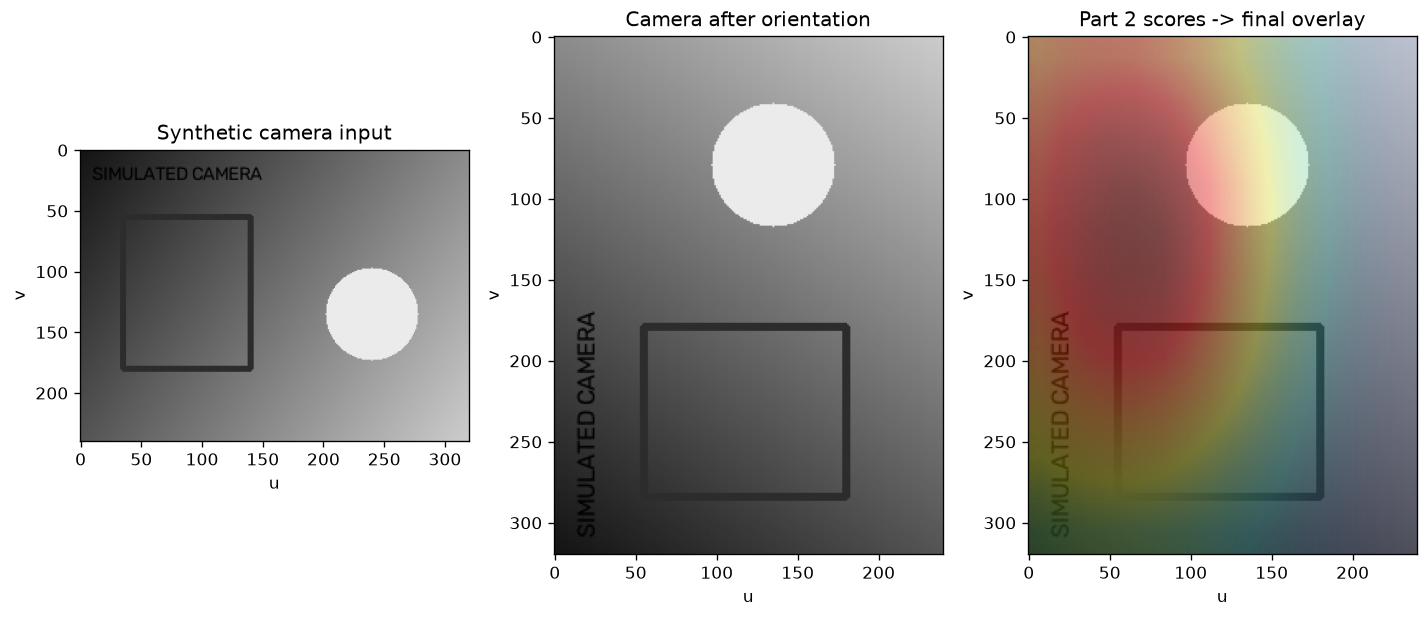

In [17]:
background=np.repeat(scene_gray[...,None],3,axis=2)
mixed=background*(1-alpha)+tint*alpha
overlay_bgr=np.rint(mixed).clip(0,255).astype(np.uint8)
pixel_v,pixel_u=np.unravel_index(np.argmax(strength),strength.shape)
print(f'ตัวอย่างพิกเซลแผนที่ที่มีค่าสูงสุด u={pixel_u}, v={pixel_v}')
print('Cgray =',background[pixel_v,pixel_u],'; Cheat BGR =',tint[pixel_v,pixel_u].astype(int))
print(f'alpha = {alpha[pixel_v,pixel_u,0]:.9f}')
show_table(['channel','before rounding','output'],
           [[name,f'{mixed[pixel_v,pixel_u,c]:.9f}',int(overlay_bgr[pixel_v,pixel_u,c])]
            for c,name in enumerate(['B','G','R'])])
fig,axes=plt.subplots(1,3,figsize=(12,6))
axes[0].imshow(received_gray,cmap='gray',vmin=0,vmax=255);axes[0].set_title('Synthetic camera input')
axes[1].imshow(scene_gray,cmap='gray',vmin=0,vmax=255);axes[1].set_title('Camera after orientation')
axes[2].imshow(cv2.cvtColor(overlay_bgr,cv2.COLOR_BGR2RGB));axes[2].set_title('Part 2 scores -> final overlay')
for ax in axes:ax.set(xlabel='u',ylabel='v')
plt.tight_layout();plt.show()


## 3.6 ตรวจเทียบกับตัวรับและตัว Overlay จริงถ้ามีไฟล์โครงการ

อ่านเฉพาะคลาส/ฟังก์ชัน ไม่เรียก main ไม่เปิดกล้องหรือ UART
ใช้ score_protocol.py ตรวจข้อความส่งทีละก้อน และ overlay_red ตรวจภาพทุกพิกเซล
คัดลอก Notebook เดี่ยวไปเครื่องอื่นยังคำนวณได้ แต่ข้ามการตรวจที่ต้องมีไฟล์เหล่านี้


In [18]:
decoder_match=None;overlay_match=None
protocol_path=find_project_file('src/PI/score_protocol.py')
if protocol_path:
    tree=ast.parse(protocol_path.read_text(encoding='utf-8'))
    decoder_class=next(n for n in tree.body if isinstance(n,ast.ClassDef) and n.name=='ScoreDecoder')
    namespace={'re':re,'time':time,'HEX6':re.compile(rb'^[0-9a-fA-F]{6}$')}
    exec(compile(ast.Module(body=[decoder_class],type_ignores=[]),str(protocol_path),'exec'),namespace)
    decoder=namespace['ScoreDecoder']()
    for start in range(0,len(score_wire),37):decoder.feed(score_wire[start:start+37])
    assert decoder.last_map==scores and decoder.map_sequence==1
    assert [decoder.mic_powers[m][0] for m in range(8)]==powers
    decoder_match=True
    print('PASS: ตัวรับจริงประกอบคะแนนและกำลังรายไมค์กลับได้ตรงกัน')
viewer_path=find_project_file('src/PI/pi_acoustic_viewer.py')
if viewer_path:
    tree=ast.parse(viewer_path.read_text(encoding='utf-8'))
    function=next(n for n in tree.body if isinstance(n,ast.FunctionDef) and n.name=='overlay_red')
    namespace={'np':np,'cv2':cv2}
    exec(compile(ast.Module(body=[function],type_ignores=[]),str(viewer_path),'exec'),namespace)
    reference_overlay=namespace['overlay_red'](scene_gray,received_scores,opacity=OPACITY,
        flip_lr=HEATMAP_FLIP_LR,flip_ud=HEATMAP_FLIP_UD,score_floor=0.0,color='jet')
    assert np.array_equal(overlay_bgr,reference_overlay)
    overlay_match=True
    print('PASS: ภาพสุดท้ายตรงกับฟังก์ชัน Overlay จริงทุกพิกเซลครบ 3 ช่องสี')
if protocol_path is None or viewer_path is None:
    print('ไม่มีไฟล์ตรวจอ้างอิงบางส่วน: การจำลองหลักยังคำนวณครบในไฟล์นี้')


PASS: ตัวรับจริงประกอบคะแนนและกำลังรายไมค์กลับได้ตรงกัน
PASS: ภาพสุดท้ายตรงกับฟังก์ชัน Overlay จริงทุกพิกเซลครบ 3 ช่องสี


# สรุปเส้นทางข้อมูลเดียวกันทั้ง 3 ส่วน

```text
พิกัดและกริด → ตารางหน่วง 192 × 8
                        ↓
เสียงจำลอง 8 × 128 → ลบค่าเฉลี่ย
                        ↓ ใช้ตารางของส่วน 1
แต่ละทิศ: หน่วง → รวม 8 ช่อง → เสียง 64 ค่า → Mean Square หนึ่งคะแนน
                        ↓ ทำครบ 192 ทิศ
คะแนน 192 ค่า → ข้อความส่ง/รับ → กริด 12 × 16
                        ↓
กลับกริด → เทียบยอด → ขยายให้เท่าภาพ → JET + alpha → ซ้อนภาพขาวดำ
```

ค่าผลของข้อมูลจำลองไม่ใช่ความแม่นยำฮาร์ดแวร์ ไม่ได้จำลองขอบนาฬิกา RAM A/B หรือเวลาส่ง
ภาพใช้ประกอบการแสดงผล ไม่ใช่กล้องที่สอบเทียบพิกเซลตรงกับเวกเตอร์ทิศแล้ว


In [19]:
show_table(['checkpoint','result'],[
    ['ตารางหน่วง',f'{Q.shape[0]} directions x {Q.shape[1]} microphones'],
    ['ข้อมูลเสียง',str(X.shape)],
    ['ทิศแหล่งเสียงจำลอง',str(SOURCE_K)],
    ['ทิศที่คะแนนสูงสุด',str(peak_index)],
    ['คะแนนส่งต่อเหมือนเดิม',str(received_scores==scores)],
    ['ขนาดภาพผลลัพธ์ (สูง,กว้าง,ช่อง)',str(overlay_bgr.shape)],
    ['เทียบ JSON ค่าหน่วง','PASS' if rom_match else 'No local reference'],
    ['เทียบคำตอบ VHDL','PASS' if golden_match else 'Different input or no local reference'],
    ['เทียบตัวรับคะแนน','PASS' if decoder_match else 'No local reference'],
    ['เทียบ Overlay','PASS' if overlay_match else 'No local reference'],
])


checkpoint                      | result                        
--------------------------------+-------------------------------
                     ตารางหน่วง | 192 directions x 8 microphones
                    ข้อมูลเสียง |                       (8, 128)
             ทิศแหล่งเสียงจำลอง |                             75
              ทิศที่คะแนนสูงสุด |                             75
          คะแนนส่งต่อเหมือนเดิม |                           True
ขนาดภาพผลลัพธ์ (สูง,กว้าง,ช่อง) |                  (320, 240, 3)
            เทียบ JSON ค่าหน่วง |                           PASS
                เทียบคำตอบ VHDL |                           PASS
               เทียบตัวรับคะแนน |                           PASS
                  เทียบ Overlay |                           PASS
